In [1]:
import pandas as pd
import os
import nibabel as nib
import numpy as np
# from pytorch_msssim import ssim, ms_ssim
from skimage.metrics import structural_similarity as ssim
# psnr
from skimage.metrics import peak_signal_noise_ratio as psnr
import re
import matplotlib.pyplot as plt 
import torch
from tqdm import tqdm
import ants

In [7]:
ablation_main_dir = "/scratch/anirudhkaushik/SYNBADD_Qualitative_1"
ab_dir_1 = "SYNBADD_128_6_5e-05_0.0_2025-04-16_04-59-48_ADNI_all_longitudinal_FinalVAETransformer_Vanilla_Fold1"
ab_dir_2 = "SYNBADD_128_6_5e-05_0.0_2025-04-19_04-35-29_ADNI_all_longitudinal_OnlyUNET_VAETransformer_Vanilla_Fold1"
ab_dir_3 = "SYNBADD_128_6_5e-05_0.0_2025-04-21_16-33-24_ADNI_all_longitudinal_OnlyUNET_NoPosEmb_VAETransformer_Vanilla_Fold1"

all_ab_dir_1_files = os.listdir(os.path.join(ablation_main_dir, ab_dir_1))
all_ab_dir_2_files = os.listdir(os.path.join(ablation_main_dir, ab_dir_2))
all_ab_dir_3_files = os.listdir(os.path.join(ablation_main_dir, ab_dir_3))


In [8]:
csv_file = "/scratch/anirudhkaushik/ADNI1_Complete_DataSplits.csv"
df = pd.read_csv(csv_file)
df = df[df[f'fold_1'] == 'test'].reset_index(drop=True)

df['Acq Date'] = pd.to_datetime(df['Acq Date'])
df = df.sort_values(by=['Subject', 'Visit', 'Acq Date']).drop_duplicates(subset=['Subject', 'Visit'], keep='last')
# Grouping subjects
subject_groups = df.groupby('Subject').apply(lambda x: x.sort_values(by='Acq Date'))
subjects = list(subject_groups.index.levels[0])


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import os

# Function to create a better visualization for all images
def visualize_all_comparisons(image_id, target_img, dir1_img, dir2_img, dir3_img, 
                             diff_dir1, diff_dir2, diff_dir3, slice_idx=64):
    """
    Comprehensive visualization of all images and difference maps
    
    Parameters:
    -----------
    image_id : str
        ID of the current image
    target_img, dir1_img, dir2_img, dir3_img : numpy.ndarray
        The original and reconstructed images
    diff_dir1, diff_dir2, diff_dir3 : numpy.ndarray
        Difference maps between target and reconstructions
    slice_idx : int
        Slice index to visualize
    """
    
    # Create a figure with custom grid layout
    fig = plt.figure(figsize=(20, 12))
    gs = GridSpec(2, 4, figure=fig, width_ratios=[1, 1, 1, 1], height_ratios=[1, 1])
    
    # Determine min and max values for consistent colormaps
    vmin_img = min(
        np.percentile(target_img[:,:,slice_idx], 1),
        np.percentile(dir1_img[:,:,slice_idx], 1),
        np.percentile(dir2_img[:,:,slice_idx], 1),
        np.percentile(dir3_img[:,:,slice_idx], 1)
    )
    vmax_img = max(
        np.percentile(target_img[:,:,slice_idx], 99),
        np.percentile(dir1_img[:,:,slice_idx], 99),
        np.percentile(dir2_img[:,:,slice_idx], 99),
        np.percentile(dir3_img[:,:,slice_idx], 99)
    )
    
    # Determine difference map color limits
    vmax_diff = max(
        np.percentile(np.abs(diff_dir1[:,:,slice_idx]), 95),
        np.percentile(np.abs(diff_dir2[:,:,slice_idx]), 95),
        np.percentile(np.abs(diff_dir3[:,:,slice_idx]), 95)
    )
    vmin_diff = -vmax_diff

    # With these fixed values:
    vmin_diff = -1.0
    vmax_diff = 1.0
    
    # Top row - Original Images
    ax_target = fig.add_subplot(gs[0, 0])
    im_target = ax_target.imshow(target_img[:,:,slice_idx], cmap='gray', 
                               vmin=vmin_img, vmax=vmax_img, origin='lower')
    ax_target.set_title('Target Image', fontsize=14)
    ax_target.set_axis_off()
    
    # Add NODER image and diff
    ax_dir1 = fig.add_subplot(gs[0, 1])
    im_dir1 = ax_dir1.imshow(dir1_img[:,:,slice_idx], cmap='gray', 
                             vmin=vmin_img, vmax=vmax_img, origin='lower')
    ax_dir1.set_title('Unet+DAFT+BidirectionalEmb Image', fontsize=14)
    ax_dir1.set_axis_off()
    
    ax_dir1_diff = fig.add_subplot(gs[1, 1])
    im_dir1_diff = ax_dir1_diff.imshow(diff_dir1[:,:,slice_idx], cmap='seismic', 
                                       vmin=vmin_diff, vmax=vmax_diff, origin='lower')
    ax_dir1_diff.set_title('Unet+DAFT+BidirectionalEmb Difference', fontsize=14)
    ax_dir1_diff.set_axis_off()
    
    # Add SynBADD image and diff
    ax_dir2 = fig.add_subplot(gs[0, 2])
    im_dir2 = ax_dir2.imshow(dir2_img[:,:,slice_idx], cmap='gray', 
                                 vmin=vmin_img, vmax=vmax_img, origin='lower')
    ax_dir2.set_title('Unet+BidirectionalEmb Image', fontsize=14)
    ax_dir2.set_axis_off()
    
    ax_dir2_diff = fig.add_subplot(gs[1, 2])
    im_dir2_diff = ax_dir2_diff.imshow(diff_dir2[:,:,slice_idx], cmap='seismic', 
                                           vmin=vmin_diff, vmax=vmax_diff, origin='lower')
    ax_dir2_diff.set_title('Unet+BidirectionalEmb Difference', fontsize=14)
    ax_dir2_diff.set_axis_off()
    
    # Add ReMIND image and diff
    ax_dir3 = fig.add_subplot(gs[0, 3])
    im_dir3 = ax_dir3.imshow(dir3_img[:,:,slice_idx], cmap='gray', 
                               vmin=vmin_img, vmax=vmax_img, origin='lower')
    ax_dir3.set_title('Unet Image', fontsize=14)
    ax_dir3.set_axis_off()
    
    ax_dir3_diff = fig.add_subplot(gs[1, 3])
    im_dir3_diff = ax_dir3_diff.imshow(diff_dir3[:,:,slice_idx], cmap='seismic', 
                                         vmin=vmin_diff, vmax=vmax_diff, origin='lower')
    ax_dir3_diff.set_title('Unet Difference', fontsize=14)
    ax_dir3_diff.set_axis_off()
    
    # Add Error Metrics
    ax_metrics = fig.add_subplot(gs[1, 0])
    ax_metrics.axis('off')
    
    # Calculate metrics
    mse_dir1 = np.mean(diff_dir1**2)
    mse_dir2 = np.mean(diff_dir2**2)
    mse_dir3 = np.mean(diff_dir3**2)
    
    mae_dir1 = np.mean(np.abs(diff_dir1))
    mae_dir2 = np.mean(np.abs(diff_dir2))
    mae_dir3 = np.mean(np.abs(diff_dir3))
    
    # Display metrics
    metrics_text = (
        f"Image ID: {image_id}\n"
        f"Slice: {slice_idx}\n\n"
        f"MSE Metrics:\n"
        f"Unet+DAFT+BidirectionalEmb: {mse_dir1:.6f}\n"
        f"Unet+BidirectionalEmb: {mse_dir2:.6f}\n"
        f"Unet: {mse_dir3:.6f}\n\n"
        f"MAE Metrics:\n"
        f"Unet+DAFT+BidirectionalEmb: {mae_dir1:.6f}\n"
        f"Unet+BidirectionalEmb: {mae_dir2:.6f}\n"
        f"Unet: {mae_dir3:.6f}"
    )
    ax_metrics.text(0.1, 0.5, metrics_text, fontsize=12, 
                   verticalalignment='center', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # Add colorbars
    cbar_ax_img = fig.add_axes([0.02, 0.15, 0.01, 0.7])
    cbar_img = fig.colorbar(im_target, cax=cbar_ax_img)
    cbar_img.set_label('Image Intensity', fontsize=12)
    
    cbar_ax_diff = fig.add_axes([0.97, 0.15, 0.01, 0.7])
    cbar_diff = fig.colorbar(im_dir1_diff, cax=cbar_ax_diff)
    cbar_diff.set_label('Difference', fontsize=12)
    
    plt.suptitle(f'Comparison of Reconstruction Methods - {image_id}', fontsize=16)
    
    return fig

def process_and_visualize_middle_slices(image_id_list):
    for image_id in image_id_list:
        try:
            # Find files
            file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
            # Find corresponding image in synbadd
            dir1_files = [f for f in all_ab_dir_1_files if image_id in f]
            if len(dir1_files) < 2:
                print(f"Skipping {image_id}: Missing SynBADD files")
                continue
                
            # Find specific synbadd files
            for k in dir1_files:
                if "_synthetic.nii.gz" in k:
                    dir1_file = k
                elif "_synthetic_field.nii.gz" in k:
                    dir1_field_path = k

            
            # Find corresponding image in synbadd
            dir2_files = [f for f in all_ab_dir_2_files if image_id in f]
            if len(dir2_files) < 2:
                print(f"Skipping {image_id}: Missing SynBADD files")
                continue
                
            # Find specific synbadd files
            for k in dir2_files:
                if "_synthetic.nii.gz" in k:
                    dir2_file = k
                elif "_synthetic_field.nii.gz" in k:
                    dir2_field_path = k

            # Find corresponding image in synbadd
            dir3_files = [f for f in all_ab_dir_3_files if image_id in f]
            if len(dir3_files) < 2:
                print(f"Skipping {image_id}: Missing SynBADD files")
                continue
                
            # Find specific synbadd files
            for k in dir3_files:
                if "_synthetic.nii.gz" in k:
                    dir3_file = k
                elif "_synthetic_field.nii.gz" in k:
                    dir3_field_path = k
            
            # Load all images
            target_img_data = load_nii(file_path)
            dir1_img_data = load_nii(os.path.join(ablation_main_dir, ab_dir_1, dir1_file))
            dir2_img_data = load_nii(os.path.join(ablation_main_dir, ab_dir_2, dir2_file))
            dir3_img_data = load_nii(os.path.join(ablation_main_dir, ab_dir_3, dir3_file))
            
            # Calculate differences
            diff_dir1 = target_img_data - dir1_img_data
            diff_dir2 = target_img_data - dir2_img_data
            diff_dir3 = target_img_data - dir3_img_data
            
            # Get middle slice
            n_slices = target_img_data.shape[2]
            middle_slice = n_slices // 2
            
            # print(f"\nVisualization for {image_id} - Middle slice ({middle_slice}):")
            
            # Visualize middle slice
            fig = visualize_all_comparisons(
                image_id, target_img_data, dir1_img_data, dir2_img_data, dir3_img_data,
                diff_dir1, diff_dir2, diff_dir3, middle_slice
            )
            plt.show()
            
        except Exception as e:
            print(f"Error processing {image_id}: {str(e)}")

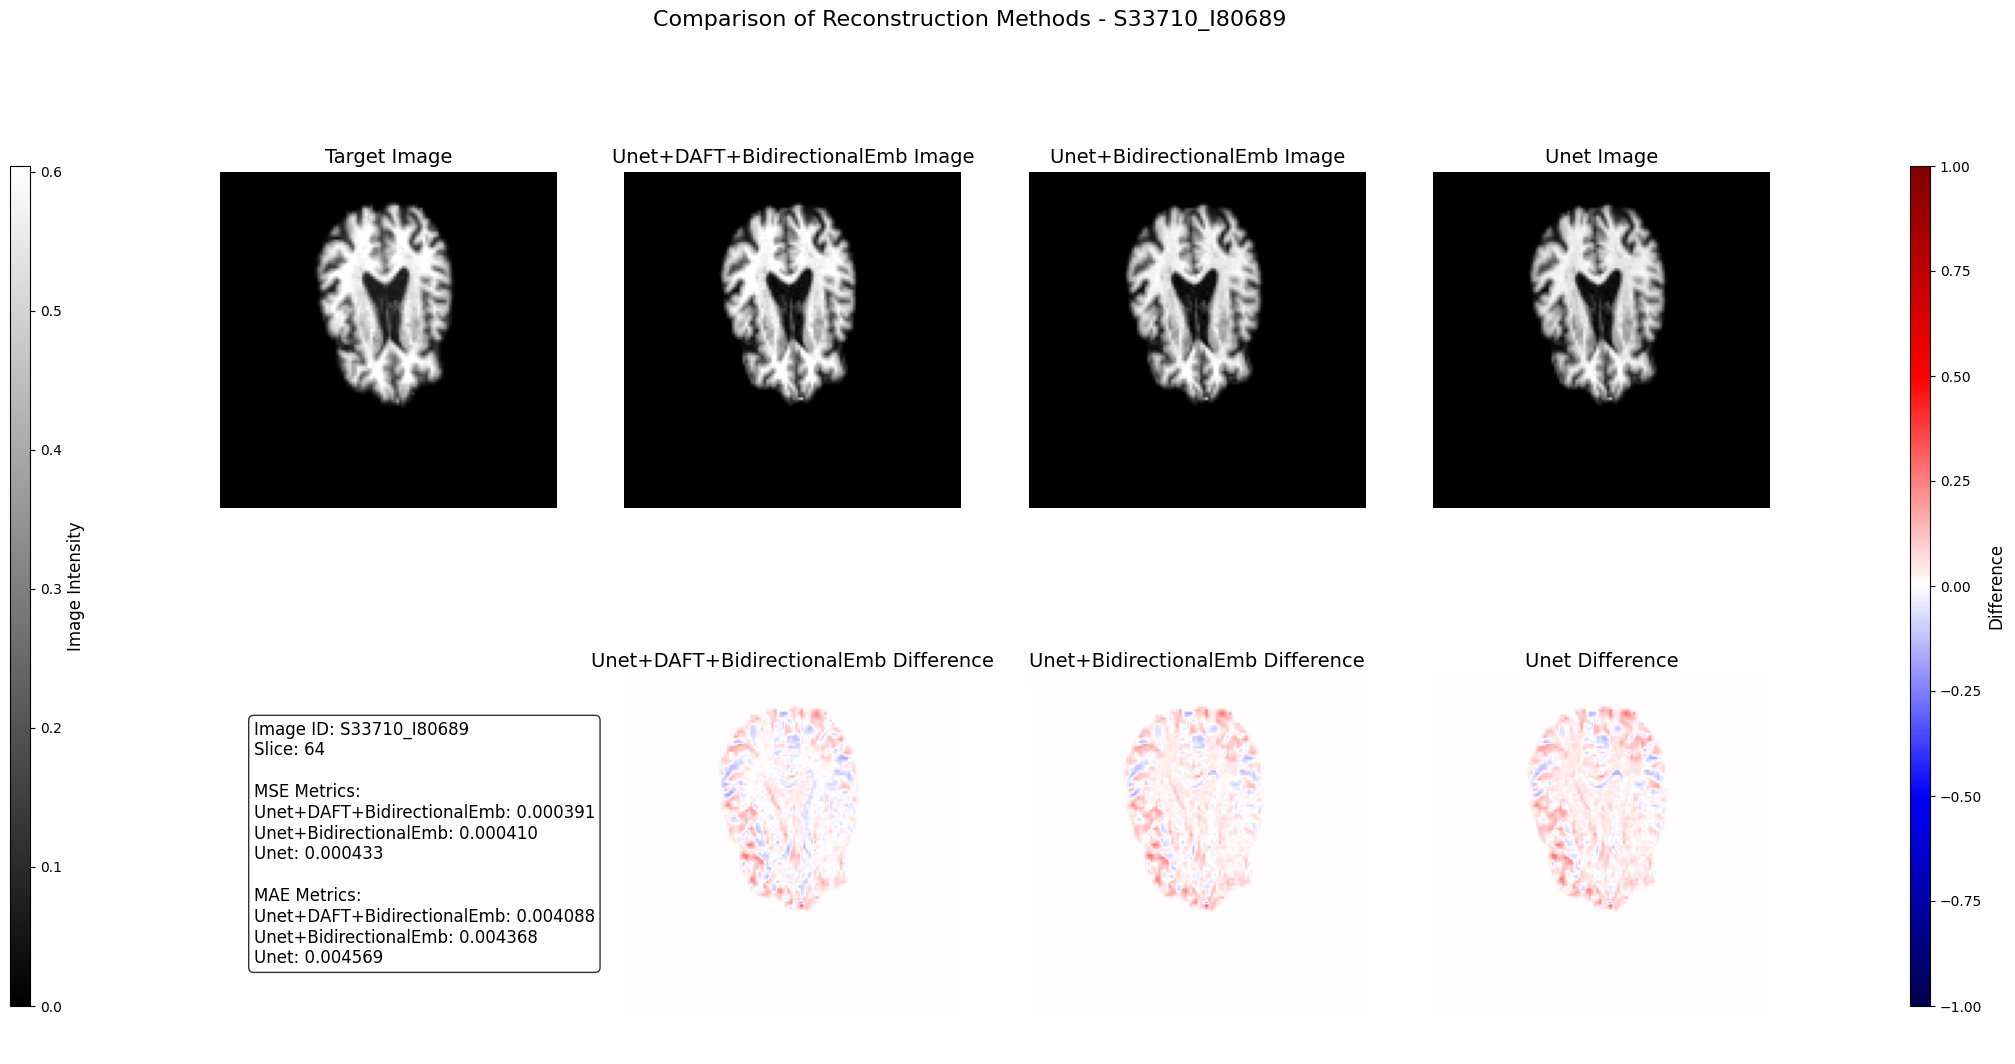

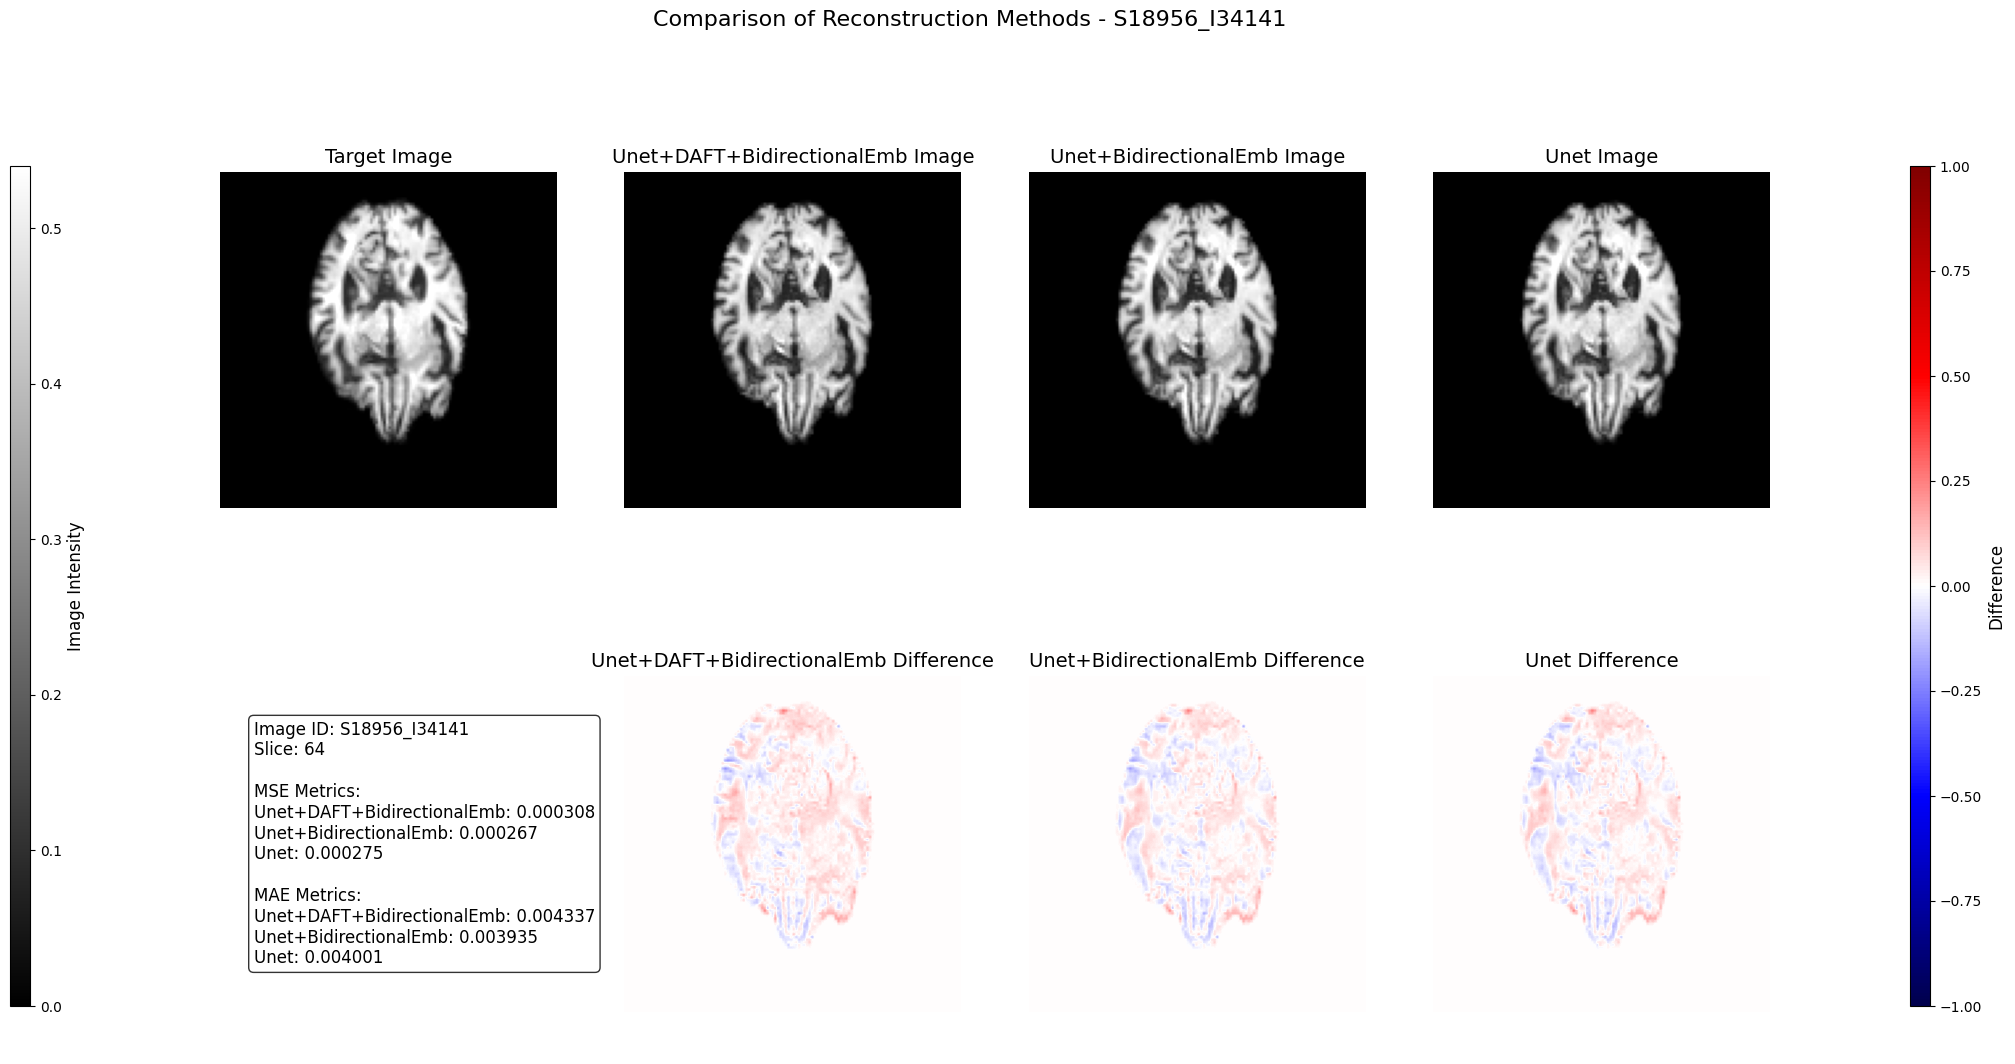

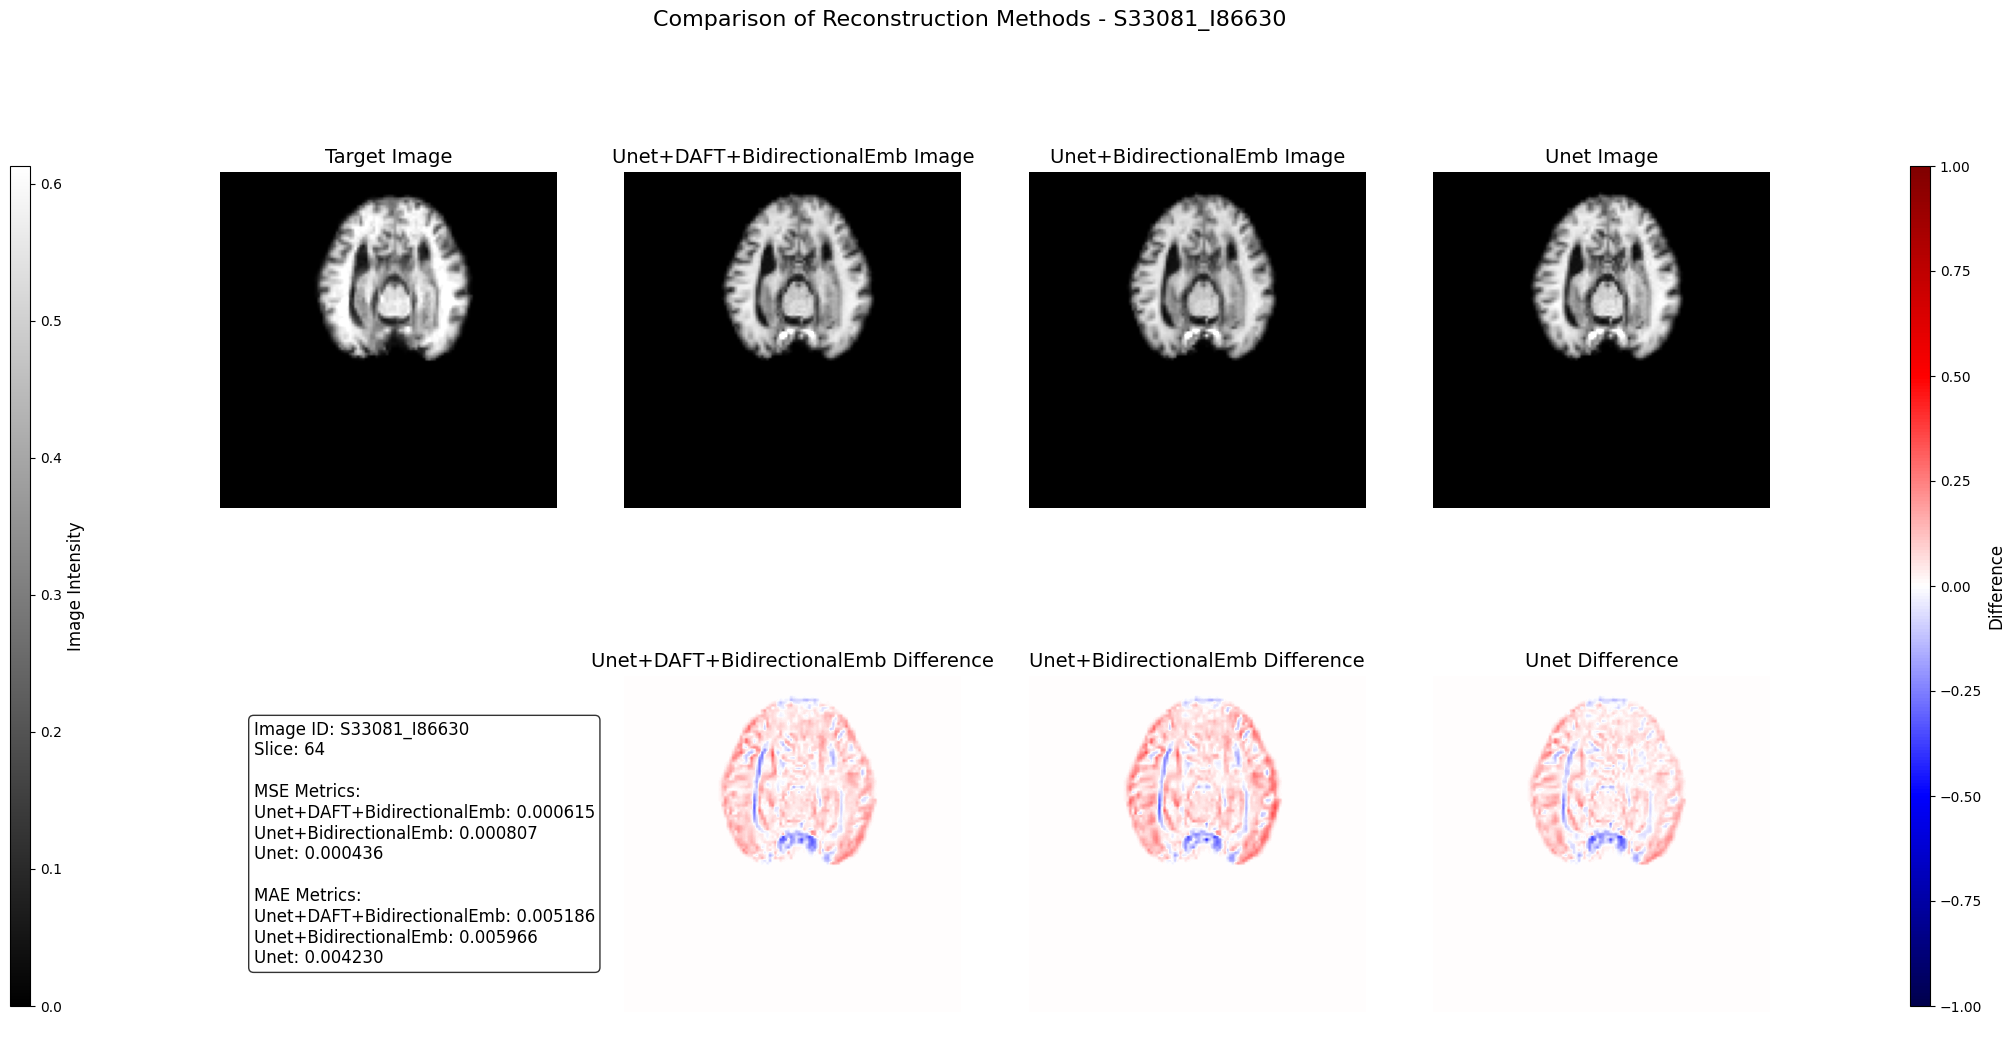

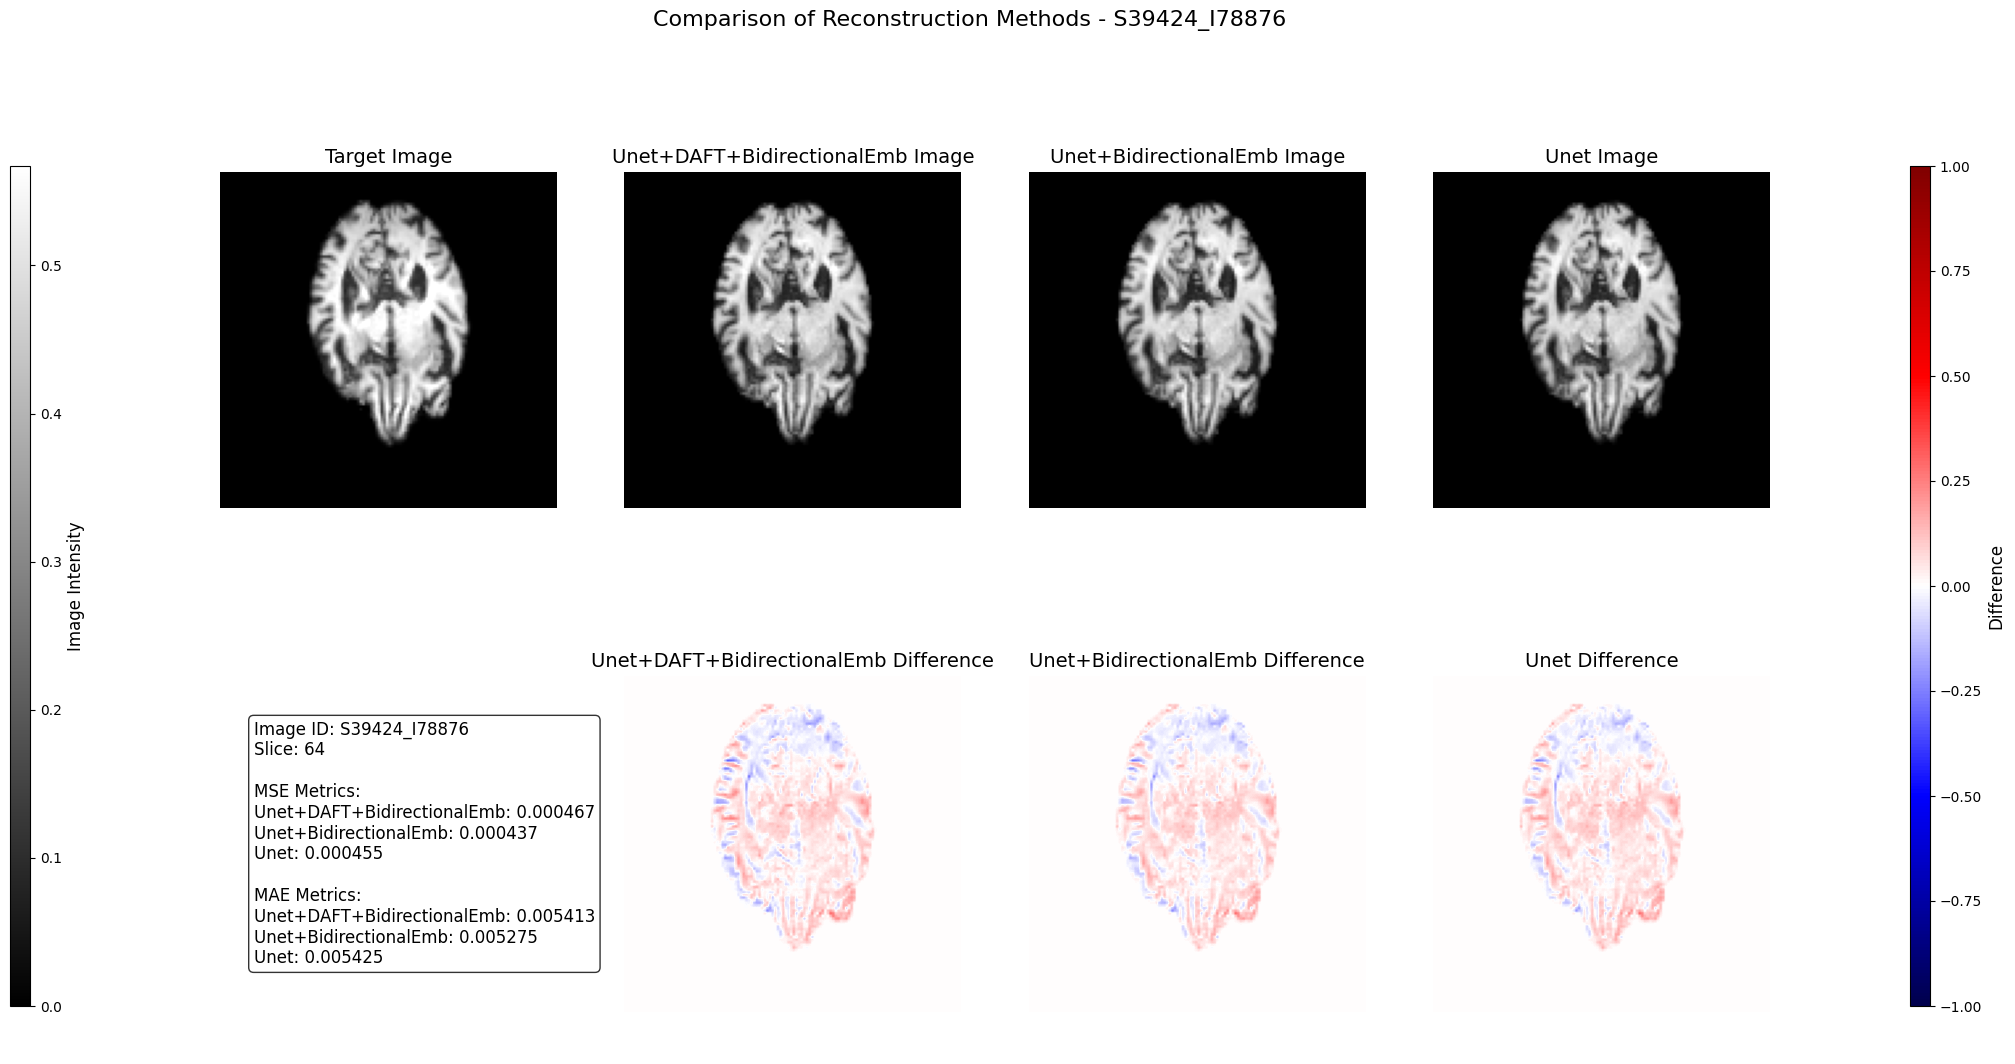

In [18]:
# Main loop through image IDs
image_id_list = ["S33710_I80689","S18956_I34141","S33081_I86630","S39424_I78876"]


# Run the visualization with middle slices only
process_and_visualize_middle_slices(image_id_list)